# plot_g6_uncertainties_aerosols_vs_solar — aerosol-type fractional variance

Python port of `plot_g6_uncertainties_aerosols_vs_solar.m`. For each IPCC-WGI
region it plots the fraction of modeling variance driven by the *aerosol type*
(`ta_var_sulf`) relative to the combined aerosol + solar variance, for `tas`
against `pr`, coloured by continental group with group-mean markers.

`*_regions1_std` are created in this folder → read from `data_py/*.npz`.
`*_regions2_std` / `*_regions3_std` are provided inputs with no in-folder
generator → read from the original `.mat`.

In [1]:
import sys
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, shaperead

regions = shaperead("IPCC-WGI-reference-regions-v4.shx")


def frac(sulf, sol):
    sulf = np.asarray(sulf, float).ravel()
    sol = np.asarray(sol, float).ravel()
    return sulf / (sol + sulf) * 100


# regions1: in-folder generated -> npz ; regions2/3: provided -> .mat
t1 = mu.load_npz("tas_regions1_std")
tas1 = frac(t1["ta_var_sulf"], t1["ta_var_solar"])
p1 = mu.load_npz("pr_regions1_std")
pr1 = frac(p1["ta_var_sulf"], p1["ta_var_solar"])

t2 = mu.loadmat("tas_regions2_std.mat")
tas2 = frac(t2["ta_var_sulf"], t2["ta_var_solar"])
p2 = mu.loadmat("pr_regions2_std.mat")
pr2 = frac(p2["ta_var_sulf"], p2["ta_var_solar"])

t3 = mu.loadmat("tas_regions3_std.mat")
tas3 = frac(t3["ta_var_sulf"], t3["ta_var_solar"])
p3 = mu.loadmat("pr_regions3_std.mat")
pr3 = frac(p3["ta_var_sulf"], p3["ta_var_solar"])

## Scatter (regions1) by continental group with group means

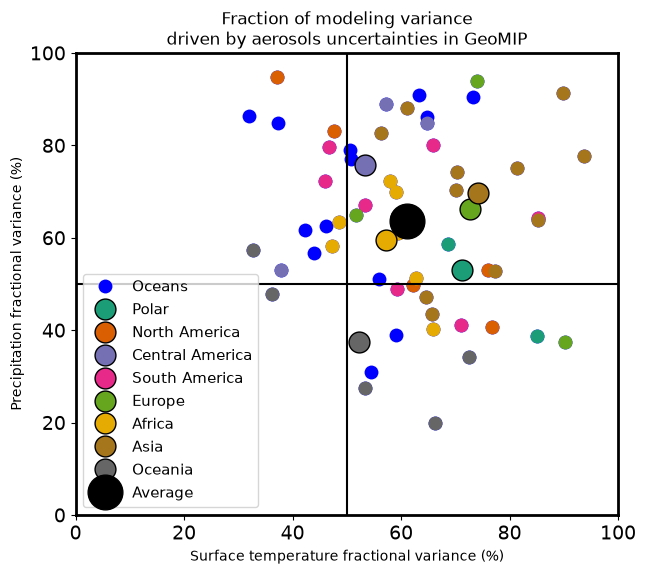

In [2]:
fc = brewermap(8, "Dark2")
col_regs = [
    [0, 44, 45], [1, 2, 3, 4, 5], [6, 7, 8],
    [9, 10, 11, 12, 13, 14, 15], [16, 17, 18, 19],
    [21, 22, 23, 24, 25, 26, 27], list(range(28, 39)), [39, 40, 41, 42, 43],
]
regions_n = ["Oceans", "Polar", "North America", "Central America",
             "South America", "Europe", "Africa", "Asia", "Oceania", "Average"]

fig, ax = plt.subplots(figsize=(7, 6))
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
handles = []
handles.append(ax.plot(tas1, pr1, "o", markerfacecolor="b",
                       markeredgecolor="none", markersize=10)[0])
for i in range(8):
    ax.plot(tas1[col_regs[i]], pr1[col_regs[i]], "o", markerfacecolor=fc[i],
            markeredgecolor="none", markersize=10)
    handles.append(ax.plot(np.nanmean(tas1[col_regs[i]]), np.nanmean(pr1[col_regs[i]]),
                           "o", markerfacecolor=fc[i], markeredgecolor="k",
                           markersize=15)[0])
handles.append(ax.plot(np.nanmean(tas1), np.nanmean(pr1), "o", markerfacecolor="k",
                       markeredgecolor="k", markersize=25)[0])
ax.plot([50, 50], [0, 100], "k")
ax.plot([0, 100], [50, 50], "k")

ax.legend(handles, regions_n, loc="lower left", fontsize=11)
ax.set_xlabel("Surface temperature fractional variance (%)", color="k")
ax.set_ylabel("Precipitation fractional variance (%)", color="k")
ax.set_title("Fraction of modeling variance\ndriven by aerosols uncertainties in GeoMIP",
             color="k")
for s in ax.spines.values():
    s.set_linewidth(2)
ax.tick_params(labelsize=14)
fig.set_facecolor("w"); ax.set_facecolor("w")
plt.show()

In [3]:
print((np.nanmean(tas1) - 50) / (100 - np.nanmean(tas1)) * 100)
print((np.nanmean(pr1) - 50) / (100 - np.nanmean(pr1)) * 100)

28.490391392255415
37.54163103827313


Original MATLAB writes `GeoMIP_uncertainties_aerosols.eps`; saved to
`py_outputs/` instead.

In [4]:
import os
os.makedirs("py_outputs", exist_ok=True)
fig.savefig("py_outputs/GeoMIP_uncertainties_aerosols.png", dpi=300, bbox_inches="tight")
print("saved py_outputs/GeoMIP_uncertainties_aerosols.png")

saved py_outputs/GeoMIP_uncertainties_aerosols.png
